In [60]:
from langgraph.graph import StateGraph , START , END
from typing import TypedDict
import os
from langchain_groq import ChatGroq
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import JsonOutputParser , PydanticOutputParser
from pydantic import BaseModel, Field


class ChatState(TypedDict):
    standard : str
    document : str
    necessary_docs : list[str]


class required_docs(BaseModel):
    req_docs : list[str] = Field(description = "list of the required documents.")

def get_rules(state : ChatState) -> ChatState:
    llm = ChatGroq(
        api_key="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",
        model="openai/gpt-oss-120b",
    )

    parser = PydanticOutputParser(pydantic_object = required_docs)

    prompt = PromptTemplate(
        template = "Give me a complete list of required documents and records for compliance with {standard} under Indian Financial Laws. /n {format_instruction}",
        input_variables = ['standard'],
        partial_variables = {'format_instruction': parser.get_format_instructions()},
    )

    chain = prompt | llm | parser
    result = chain.invoke({'standard' : state["standard"]})

    print(result)

    return {'necessary_docs' : result.req_docs}


graph = StateGraph(ChatState)

graph.add_node('get_rules' , get_rules)

graph.add_edge(START, "get_rules")
graph.add_edge("get_rules", END)

workflow = graph.compile()

print(workflow)








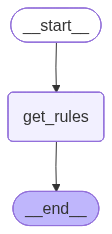

: 

In [ ]:
workflow


In [ ]:
initial_state = {
    "standard" : "Schedule 3"
}


: 

In [ ]:
workflow.invoke(initial_state)

req_docs=['Balance Sheet (Schedule\u202fIII format)', 'Statement of Profit and Loss (Schedule\u202fIII format)', 'Statement of Changes in Equity', 'Cash Flow Statement', 'Notes to Accounts (as prescribed in Schedule\u202fIII)', 'Schedule of Fixed Assets and Depreciation', 'Schedule of Investments', 'Schedule of Borrowings and Loans', 'Schedule of Related Party Transactions', 'Schedule of Contingent Liabilities and Commitments', 'Schedule of Share Capital, Share Premium, Reserves and Surplus', 'Management Discussion and Analysis (MD&A) (if required)', 'Auditor’s Report on compliance with Schedule\u202fIII', 'Board’s Report containing the financial statements', 'Working Capital Schedule', 'Inventory Register and Valuation Schedule', 'Receivables and Payables Aging Reports', 'Bank Reconciliation Statements', 'Tax Computation Statements and Returns (Income Tax, GST)', 'Statutory Registers (Members, Directors, Charges, etc.)', 'Minutes of Board and General Meetings approving the financial s

{'standard': 'Schedule 3',
 'necessary_docs': ['Balance Sheet (Schedule\u202fIII format)',
  'Statement of Profit and Loss (Schedule\u202fIII format)',
  'Statement of Changes in Equity',
  'Cash Flow Statement',
  'Notes to Accounts (as prescribed in Schedule\u202fIII)',
  'Schedule of Fixed Assets and Depreciation',
  'Schedule of Investments',
  'Schedule of Borrowings and Loans',
  'Schedule of Related Party Transactions',
  'Schedule of Contingent Liabilities and Commitments',
  'Schedule of Share Capital, Share Premium, Reserves and Surplus',
  'Management Discussion and Analysis (MD&A) (if required)',
  'Auditor’s Report on compliance with Schedule\u202fIII',
  'Board’s Report containing the financial statements',
  'Working Capital Schedule',
  'Inventory Register and Valuation Schedule',
  'Receivables and Payables Aging Reports',
  'Bank Reconciliation Statements',
  'Tax Computation Statements and Returns (Income Tax, GST)',
  'Statutory Registers (Members, Directors, Charge

: 

In [ ]:
final_result = workflow.invoke(initial_state)


req_docs=['Balance Sheet in Schedule III format', 'Statement of Profit and Loss (Income Statement) in Schedule III format', 'Statement of Changes in Equity', 'Cash Flow Statement', 'Notes to the Financial Statements (including accounting policies)', 'Schedule of Fixed Assets', 'Schedule of Investments', 'Schedule of Borrowings and Loans', 'Schedule of Related Party Transactions', 'Statement of Contingent Liabilities and Commitments', 'Management Discussion and Analysis (MD&A) Report', "Auditor's Report", "Board's Report", 'Corporate Governance Report', 'Statutory Registers (Register of Members, Directors, etc.)', 'Minutes of Board Meetings', 'Minutes of General Meeting', 'Compliance Certificate under Section\u202f134(3) of the Companies Act, 2013', 'Declaration of Solvency (where applicable)', 'Annual Return (Form MGT‑7)', 'Form AOC‑4 (Financial Statements)', 'Form ADT‑1 (Declaration of Directors)', 'Tax Audit Report (if applicable under Income Tax Act)', 'GST Returns and Reconciliatio

: 

: 

In [ ]:
final_result

{'standard': 'Schedule 3',
 'necessary_docs': ['Balance Sheet in Schedule III format',
  'Statement of Profit and Loss (Income Statement) in Schedule III format',
  'Statement of Changes in Equity',
  'Cash Flow Statement',
  'Notes to the Financial Statements (including accounting policies)',
  'Schedule of Fixed Assets',
  'Schedule of Investments',
  'Schedule of Borrowings and Loans',
  'Schedule of Related Party Transactions',
  'Statement of Contingent Liabilities and Commitments',
  'Management Discussion and Analysis (MD&A) Report',
  "Auditor's Report",
  "Board's Report",
  'Corporate Governance Report',
  'Statutory Registers (Register of Members, Directors, etc.)',
  'Minutes of Board Meetings',
  'Minutes of General Meeting',
  'Compliance Certificate under Section\u202f134(3) of the Companies Act, 2013',
  'Declaration of Solvency (where applicable)',
  'Annual Return (Form MGT‑7)',
  'Form AOC‑4 (Financial Statements)',
  'Form ADT‑1 (Declaration of Directors)',
  'Tax A

: 

In [ ]:
``

: 

In [ ]:
``

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 

: 